# Zadanie 1 - Programowanie równoległe z wykorzystaniem GPU
Poniżej znajduje się rozwiązanie zadania 1 zdefiniowane w dokumencie Temat 2.pdf.

In [3]:
import numpy as np
import cupy as cp
import time

def cpu_gpu(N):
  A_cpu = np.random.rand(N, N).astype(np.float32)
  B_cpu = np.random.rand(N, N).astype(np.float32)

  start_cpu = time.time()
  C_cpu = np.matmul(A_cpu, B_cpu)
  end_cpu = time.time()
  cpu_time = end_cpu - start_cpu
  print(f"Mnożenie macierzy na CPU trwało: {cpu_time:.5f} sekund.")

  A_gpu = cp.array(A_cpu)
  B_gpu = cp.array(B_cpu)

  start_gpu = time.time()
  C_gpu = cp.matmul(A_gpu, B_gpu)
  cp.cuda.Stream.null.synchronize()
  end_gpu = time.time()
  gpu_time = end_gpu - start_gpu
  print(f"Mnożenie macierzy na GPU trwało: {gpu_time:.5f} sekund.")

  speedup = cpu_time / gpu_time if gpu_time > 0 else 0
  print(f"GPU jest {speedup:.2f}x szybsze niż CPU dla N={N}.")
  return [cpu_time, gpu_time]

In [1]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"
!pip install pycuda

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 75.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.8/101.8 kB 12.2 MB/s eta 0:00:00
  Created wheel for pycuda: filename=pycuda-2026.1-cp313-cp313-linux_x86_64.whl size=5281391 sha256=aa982603dfa7d615b7dc1d3526c404fa648c55da8597a75ca5d32da7371a838e
  Stored in directory: /root/.cache/pip/wheels/ce/26/46/c519675fcb0e5e17bab8e85b6676528c40d12d794182340e85
Successfully built pycuda


In [4]:
import numpy as np
import time
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule

def pycuda(N):
  A_cpu = np.random.rand(N, N).astype(np.float32)
  B_cpu = np.random.rand(N, N).astype(np.float32)
  C_cpu = np.empty((N, N), np.float32)

  kernel_code = """
  __global__ void matrixMul(float *A, float *B, float *C, int N) {
      int row = blockIdx.y * blockDim.y + threadIdx.y;
      int col = blockIdx.x * blockDim.x + threadIdx.x;
      float sum = 0.0;
      if(row < N && col < N) {
          for (int k = 0; k < N; k++) {
              sum += A[row * N + k] * B[k * N + col];
          }
          C[row * N + col] = sum;
      }
  }
  """

  mod = SourceModule(kernel_code)
  matrixMul = mod.get_function("matrixMul")

  A_gpu = cuda.mem_alloc(A_cpu.nbytes)
  B_gpu = cuda.mem_alloc(B_cpu.nbytes)
  C_gpu = cuda.mem_alloc(C_cpu.nbytes)

  cuda.memcpy_htod(A_gpu, A_cpu)
  cuda.memcpy_htod(B_gpu, B_cpu)

  block_size = (32, 32, 1)
  grid_size = (int(N/32), int(N/32), 1)

  start_time = time.time()

  matrixMul(A_gpu, B_gpu, C_gpu, np.int32(N), block=block_size, grid=grid_size)
  cuda.Context.synchronize()

  end_time = time.time()

  cuda.memcpy_dtoh(C_cpu, C_gpu)
  gpu_pycuda = end_time - start_time
  print(f"Niskopoziomowe mnożenie macierzy na GPU (PyCUDA) trwało: {gpu_pycuda:.5f} sekund.")

  A_gpu.free()
  B_gpu.free()
  C_gpu.free()
  return gpu_pycuda

Mnożenie macierzy na CPU trwało: 0.00034 sekund.
Mnożenie macierzy na GPU trwało: 0.00037 sekund.
GPU jest 0.90x szybsze niż CPU dla N=128.
Mnożenie macierzy na CPU trwało: 0.01819 sekund.
Mnożenie macierzy na GPU trwało: 0.00116 sekund.
GPU jest 15.70x szybsze niż CPU dla N=1024.
Niskopoziomowe mnożenie macierzy na GPU (PyCUDA) trwało: 0.00684 sekund.
Mnożenie macierzy na CPU trwało: 0.14565 sekund.
Mnożenie macierzy na GPU trwało: 0.00734 sekund.
GPU jest 19.83x szybsze niż CPU dla N=2048.
Niskopoziomowe mnożenie macierzy na GPU (PyCUDA) trwało: 0.05367 sekund.
Mnożenie macierzy na CPU trwało: 0.49677 sekund.
Mnożenie macierzy na GPU trwało: 0.02299 sekund.
GPU jest 21.61x szybsze niż CPU dla N=3072.
Niskopoziomowe mnożenie macierzy na GPU (PyCUDA) trwało: 0.18018 sekund.
Mnożenie macierzy na CPU trwało: 1.15946 sekund.
Mnożenie macierzy na GPU trwało: 0.02631 sekund.
GPU jest 44.08x szybsze niż CPU dla N=4096.
Niskopoziomowe mnożenie macierzy na GPU (PyCUDA) trwało: 0.33217 sekund.


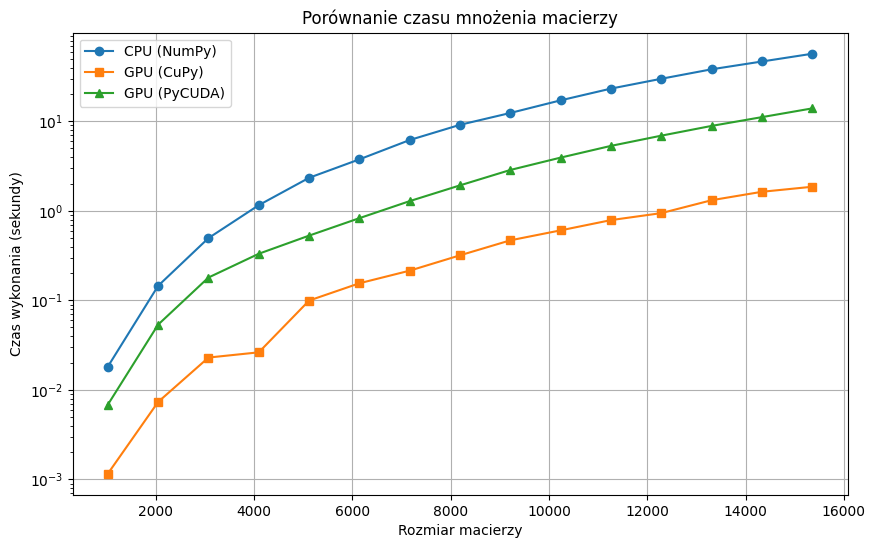

In [6]:
import matplotlib.pyplot as plt

Ns = [1024*i for i in range(1, 16)]
cpu_times = []
gpu_times = []
pycuda_times = []
cpu_gpu(128)
for N in Ns:
  cpu_in, gpu_in = cpu_gpu(N)
  cpu_times.append(cpu_in)
  gpu_times.append(gpu_in)
  pycuda_times.append(pycuda(N))

plt.figure(figsize=(10, 6))
plt.plot(Ns, cpu_times, label='CPU (NumPy)', marker='o')
plt.plot(Ns, gpu_times, label='GPU (CuPy)', marker='s')
plt.plot(Ns, pycuda_times, label='GPU (PyCUDA)', marker='^')
plt.xlabel('Rozmiar macierzy')
plt.ylabel('Czas wykonania (sekundy)')
plt.title('Porównanie czasu mnożenia macierzy')
plt.legend()
plt.grid(True)
plt.yscale('log')
plt.show()